# VAE for Bearing Vibration
**Author:** Min Khaung Min Lwin

**Dataset:** Paderborn Bearing Dataset on Zenodo (DOI 10.5281/zenodo.15845309), https://zenodo.org/records/15845309 .

This dataset was created by Lessmeier et al. (2016) at Paderborn University, and the Zenodo upload is a copy. Later these are re-upload by Jurgen van den Hoogen (Osnabrück University), and published July 2025 under a CC BY 4.0 licence for copy.

**Task type:** I'll train a 1D-convolutional VAE on vibration windows from the Paderborn University bearing dataset. The training will be on healthy K001–K004, test on unseen healthy K005–K006 and on real damage KA04/KA15/KA16 (outer race) and KI04/KI14/KI16 (inner race).

With this we can generate new signals, explore the latent space, and test whether reconstruction error separates healthy from damaged bearings. 


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, torch
from scipy.io import loadmat
from pathlib import Path

DATA = Path("data/paderborn")
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(torch.__version__, device)

f = DATA / "K001" / "N15_M07_F10_K001_1.mat"
m = loadmat(f, simplify_cells=True)
print([k for k in m if not k.startswith("__")])
rec = m[f.stem]
print(type(rec), rec.keys() if isinstance(rec, dict) else "")
for ch in rec["Y"]:
    print(ch["Name"], np.asarray(ch["Data"]).shape)

2.15.0 mps
['N15_M07_F10_K001_1']
<class 'dict'> dict_keys(['Info', 'X', 'Y', 'Description'])
force (16001,)
phase_current_1 (256001,)
phase_current_2 (256001,)
speed (16001,)
temp_2_bearing_module (5,)
torque (16001,)
vibration_1 (256001,)


#### Note: I will load every file and look at the signals

In [2]:
BEARINGS = {"K001": "healthy", "K002": "healthy", "K003": "healthy", "K004": "healthy",
            "K005": "healthy", "K006": "healthy",
            "KA04": "outer_race", "KA15": "outer_race", "KA16": "outer_race",
            "KI04": "inner_race", "KI14": "inner_race", "KI16": "inner_race"}
FS = 64000

def load_vibration(path):
    """Return the vibration_1 channel of one Paderborn recording as float32."""
    rec = loadmat(path, simplify_cells=True)[path.stem]
    ch = next(c for c in rec["Y"] if c["Name"] == "vibration_1")
    return np.asarray(ch["Data"], dtype=np.float32)

signals, rows = {}, []
for b, label in BEARINGS.items():
    for f in sorted((DATA / b).glob("N15_M07_F10_*.mat")):
        x = load_vibration(f)
        signals[f.stem] = x
        rows.append({"file": f.stem, "bearing": b, "label": label, "n": len(x),
                     "rms": float(np.sqrt(np.mean(x**2))), "kurtosis": float(pd.Series(x).kurt())})
meta = pd.DataFrame(rows)
print(len(meta), "recordings")
meta.groupby(["label", "bearing"])[["n", "rms", "kurtosis"]].mean().round(3)

240 recordings


n    rms  kurtosis
label      bearing                            
healthy    K001     256261.75  0.403    10.687
           K002     257121.15  0.230    12.033
           K003     256760.60  0.362    12.788
           K004     256001.00  0.171     2.118
           K005     256259.45  0.199     1.215
           K006     256903.45  0.381    11.760
inner_race KI04     256181.40  0.365     2.202
           KI14     257635.05  0.227     0.806
           KI16     256932.10  0.390     2.081
outer_race KA04     256385.70  0.484     2.621
           KA15     256000.75  0.208     1.363
           KA16     256269.55  0.600     3.012

In [3]:
import os; os.makedirs("figures", exist_ok=True)

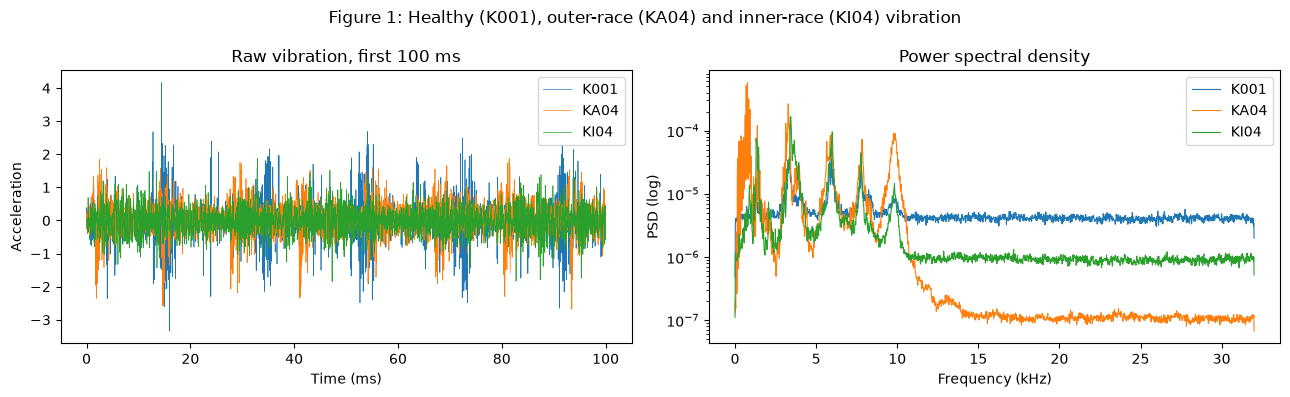

In [4]:
# Figure 1: raw vibration (first 0.1 s) and average spectrum for one bearing per class
from scipy.signal import welch
examples = ["N15_M07_F10_K001_1", "N15_M07_F10_KA04_1", "N15_M07_F10_KI04_1"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in examples:
    x = signals[name]
    t = np.arange(6400) / FS
    axes[0].plot(t * 1000, x[:6400], lw=0.5, label=name.split("_")[-2])
    f, p = welch(x, fs=FS, nperseg=4096)
    axes[1].semilogy(f / 1000, p, lw=0.8, label=name.split("_")[-2])
axes[0].set_title("Raw vibration, first 100 ms"); axes[0].set_xlabel("Time (ms)"); axes[0].set_ylabel("Acceleration")
axes[1].set_title("Power spectral density"); axes[1].set_xlabel("Frequency (kHz)"); axes[1].set_ylabel("PSD (log)")
for ax in axes: ax.legend()
plt.suptitle("Figure 1: Healthy (K001), outer-race (KA04) and inner-race (KI04) vibration")
plt.tight_layout(); plt.savefig("figures/fig1_samples.png", dpi=150); plt.show()